<a href="https://colab.research.google.com/github/fiafiaw/data_science/blob/main/25sept.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Import Library
import numpy as np
import pandas as pd
import statsmodels.api as sm
# Membuat DataFrame dari data yang diberikan
data = {
'Partisipan': np.arange(1, 11),
'PMakan': [50, 40, 60, 55, 45, 65, 70, 75, 80, 90],
'PTranspor': [20, 25, 30, 35, 40, 50, 55, 60, 65, 70],
'BB': [60, 55, 65, 70, 62, 75, 80, 85, 90, 95]}
df = pd.DataFrame(data)
# Memisahkan variabel independen dan dependen
X = df[['PMakan', 'PTranspor']]
y = df['BB']
X = sm.add_constant(X) # Menambahkan kolom konstanta untuk intercept
model = sm.OLS(y, X) # Membangun model regresi
results = model.fit()
print(results.summary()) # Menampilkan hasil

                            OLS Regression Results                            
Dep. Variable:                     BB   R-squared:                       0.985
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     234.6
Date:                Thu, 24 Sep 2026   Prob (F-statistic):           3.85e-07
Time:                        23:46:59   Log-Likelihood:                -18.626
No. Observations:                  10   AIC:                             43.25
Df Residuals:                       7   BIC:                             44.16
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         26.9870      2.879      9.374      0.0

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import plotly.graph_objects as go

# 1. PERBAIKAN DATA: 990 diubah menjadi 90 agar data tidak outlier ekstrem
data = {
    "Partisipan": np.arange(1, 11),
    "Peng Makanan": [50, 40, 60, 55, 45, 65, 70, 75, 80, 90],
    "Peng Transportasi": [20, 25, 30, 35, 40, 50, 55, 60, 65, 70],
    "Berat Badan": [60, 55, 65, 70, 62, 75, 80, 85, 90, 95]
}
df = pd.DataFrame(data)

# 2. Variabel independen
X = df[["Peng Makanan", "Peng Transportasi"]]

# 3. Variabel dependen
y = df["Berat Badan"]

# 4. MENAMBAHKAN INTERCEPT
X_model = sm.add_constant(X)

# 5. ESTIMASI MODEL OLS
model = sm.OLS(y, X_model)
results = model.fit()

# 6. MENAMPILKAN RINGKASAN HASIL REGRESI
print("\n")
print("=" * 70)
print(" HASIL REGRESI LINEAR BERGANDA")
print("=" * 70)
print(results.summary())

# 7. MENGAMBIL KOEFISIEN REGRESI
intercept = results.params["const"]
coef_makanan = results.params["Peng Makanan"]
coef_transportasi = results.params["Peng Transportasi"]
r_squared = results.rsquared
adjusted_r_squared = results.rsquared_adj

# 8. MEMBUAT PERSAMAAN REGRESI
persamaan = (
    f"Ŷ = {intercept:.3f}"
    f" + ({coef_makanan:.3f}) X1"
    f" + ({coef_transportasi:.3f}) X2"
)
print("\n")
print("=" * 70)
print(" PERSAMAAN REGRESI")
print("=" * 70)
print(persamaan)
print(f"\nR2 = {r_squared:.4f}")
print(f"Adjusted R2 = {adjusted_r_squared:.4f}")

# 9. MENGHITUNG NILAI PREDIKSI
df["Prediksi"] = results.predict(X_model)
print("\n")
print("=" * 70)
print(" DATA AKTUAL & PREDIKSI")
print("=" * 70)

# 10. PERBAIKAN SYNTAX ERROR DI SINI: Kurung siku & kurung tutup diperbaiki
print(
    df[["Partisipan", "Peng Makanan", "Peng Transportasi", "Berat Badan", "Prediksi"]].round(2)
)

# 11. MEMBUAT GRID UNTUK BIDANG REGRESI
x1 = np.linspace(df["Peng Makanan"].min(), df["Peng Makanan"].max(), 40)
x2 = np.linspace(df["Peng Transportasi"].min(), df["Peng Transportasi"].max(), 40)
X1, X2 = np.meshgrid(x1, x2)

# 12. MENGHITUNG NILAI Y PADA BIDANG REGRESI
Y = (intercept + coef_makanan * X1 + coef_transportasi * X2)

# 13. MEMBUAT FIGURE 3D
fig = go.Figure()

# 14. MENAMPILKAN DATA AKTUAL
fig.add_trace(
    go.Scatter3d(
        x=df["Peng Makanan"],
        y=df["Peng Transportasi"],
        z=df["Berat Badan"],
        mode="markers",
        marker=dict(
            size=7,
            color="red",
            opacity=0.9
        ),
        name="Data Aktual",
        text=[f"Partisipan {p}" for p in df["Partisipan"]],
        hovertemplate=(
            "<b>%{text}</b><br>"
            "Peng. Makanan: %{x}<br>"
            "Peng. Transportasi: %{y}<br>"
            "Berat Badan: %{z}"
            "<extra></extra>"
        )
    )
)

# 15. MENAMPILKAN BIDANG REGRESI
fig.add_trace(
    go.Surface(
        x=X1, y=X2, z=Y,
        opacity=0.60,
        colorscale="Viridis",
        name="Regression Plane",
        hovertemplate=(
            "Peng. Makanan: %{x:.2f}<br>"
            "Peng. Transportasi: %{y:.2f}<br>"
            "Prediksi Y: %{z:.2f}"
            "<extra></extra>"
        )
    )
)

# 16. MENGATUR TAMPILAN GRAFIK
fig.update_layout(
    title={
        "text": (
            "REGRESI LINEAR BERGANDA 3D"
            "<br>"
            f"<sup>{persamaan} | "
            f"R2 = {r_squared:.3f}</sup>"
        ),
        "x": 0.5
    },
    scene={
        "xaxis": {"title": "Pengeluaran Makanan (X1)"},
        "yaxis": {"title": "Pengeluaran Transportasi (X2)"},
        "zaxis": {"title": "Berat Badan (Y)"}
    },
    width=1000,
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 100},
    legend={"x": 0.02, "y": 0.98}
)

# 17. MENAMPILKAN GRAFIK
fig.show()



 HASIL REGRESI LINEAR BERGANDA
                            OLS Regression Results                            
Dep. Variable:            Berat Badan   R-squared:                       0.985
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     234.6
Date:                Thu, 24 Sep 2026   Prob (F-statistic):           3.85e-07
Time:                        23:53:38   Log-Likelihood:                -18.626
No. Observations:                  10   AIC:                             43.25
Df Residuals:                       7   BIC:                             44.16
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const

In [ ]:
import numpy as np
from scipy import stats
data = np.array([167, 184, 192, 198, 200, 202, 210, 211, 212, 215, 216, 217,218, 219, 220, 221, 222, 223, 224, 225, 226, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241])
# Perform normality test
result = stats.normaltest(data)
# Extract test statistics and p-value
test_statistic = result.statistic
p_value = result.pvalue
# Print the results
print("Test Statistic:", test_statistic)
print("p-value:", p_value)

Test Statistic: 14.0629722468609
p-value: 0.0008836176394721423


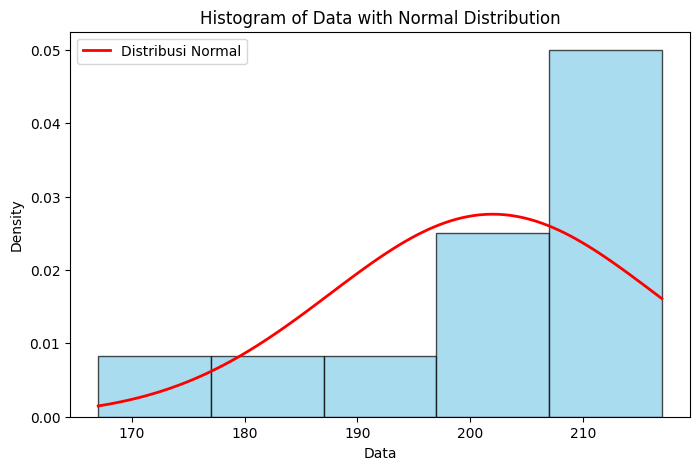

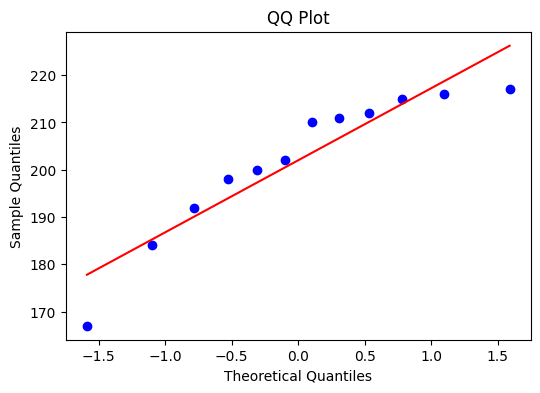

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# 1. PERBAIKAN: Menutup kurung array data yang terpotong
data = np.array([167, 184, 192, 198, 200, 202, 210, 211, 212, 215, 216, 217])

# Membuat figure untuk ukuran grafik pertama
plt.figure(figsize=(8, 5))

# 2. PERBAIKAN: Melengkapi parameter 'edgecolor' dan menutup kurung fungsi
plt.hist(data, bins='auto', density=True, alpha=0.7, color='skyblue', edgecolor='black')

# Plot kurva distribusi normal
mu, std = np.mean(data), np.std(data)
x = np.linspace(np.min(data), np.max(data), 100)
y = stats.norm.pdf(x, mu, std)
plt.plot(x, y, color='red', linewidth=2, label='Distribusi Normal')

# Set plot title and labels
plt.title('Histogram of Data with Normal Distribution')
plt.xlabel('Data')
plt.ylabel('Density') # Diganti menjadi 'Density' karena density=True pada hist
plt.legend()

# Show the plot
plt.show()

# ==========================================

# QQ plot
plt.figure(figsize=(6, 4))
stats.probplot(data, dist="norm", plot=plt)

# Set plot title and labels
plt.title('QQ Plot')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')

# Show the plot
plt.show()

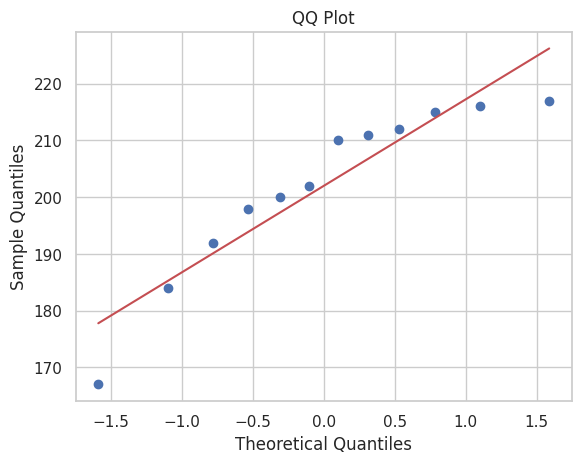

In [ ]:
# Python untuk visualisasi normalitas data menggunakan QQ plot dengan menggu
import numpy as np
import seaborn as sns
import scipy.stats as stats
data = np.array([167, 184, 192, 198, 200, 202, 210, 211, 212, 215, 216, 217,])
# Generate QQ plot
sns.set(style="whitegrid")
stats.probplot(data, dist="norm", plot=sns.mpl.pyplot)
# Set plot title and labels
sns.mpl.pyplot.title('QQ Plot')
sns.mpl.pyplot.xlabel('Theoretical Quantiles')
sns.mpl.pyplot.ylabel('Sample Quantiles')
# Show the plot
sns.mpl.pyplot.show()

In [ ]:
import numpy as np
from scipy import stats
data = np.array([167, 184, 192, 198, 200, 202, 210, 211, 212, 215, 216, 217])
# Kolmogorov-Smirnov Test
ks_statistic, ks_pvalue = stats.kstest(data, 'norm')
print("Kolmogorov-Smirnov Test:")
print("Test Statistic:", ks_statistic)
print("p-value:", ks_pvalue)
# Shapiro-Wilk Test
sw_statistic, sw_pvalue = stats.shapiro(data)
print("\nShapiro-Wilk Test:")
print("Test Statistic:", sw_statistic)
print("p-value:", sw_pvalue)
# Jarque-Bera Test
jb_statistic, jb_pvalue = stats.jarque_bera(data)
print("\nJarque-Bera Test:")
print("Test Statistic:", jb_statistic)
print("p-value:", jb_pvalue)

Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0

Shapiro-Wilk Test:
Test Statistic: 0.8781440854620193
p-value: 0.08298105386096202

Jarque-Bera Test:
Test Statistic: 2.4154126565554366
p-value: 0.29888203109494
